# Small-tree Hessian experiments
**Research findings | November 19, 2026**

**Question:** What Hessian information does a fitted tree provide, and does combining it improve accuracy? Motivated by Nathan's November 16 discussion (15:16–15:20). Keep the same 121-point noiseless quadratic grid, $H=\begin{pmatrix}4&1.5\\1.5&3\end{pmatrix}$, and change depth. The companion sklearn notebook explains the formulas. Here we test consequences.

**Why:** Reuse the same estimator and plotting helpers so this notebook runs independently.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from itertools import combinations
from IPython.display import display
H_true = np.array([[4.,1.5],[1.5,3.]])
def f(x1,x2):
    return .7-x1+2*x2+2*x1**2+1.5*x1*x2+1.5*x2**2
grid = np.linspace(0,1,11)
X = np.array([(x1,x2) for x1 in grid for x2 in grid])
y = f(*X.T)
def fit_tree(depth, X=X, y=y):
    return DecisionTreeRegressor(max_depth=depth, min_samples_leaf=4, random_state=0).fit(X,y)

def get_width(l1, u1, l2, u2, axis):
    if axis == 0:
        return u1 - l1
    elif axis == 1:
        return u2 - l2
    raise ValueError('Invalid split axis')


def gradient_estimate(mean_left, mean_right, width):
    return 2*(mean_right - mean_left)/width


def effective_location(l1, u1, l2, u2, tau, axis):
    if axis == 0:
        m1 = (l1 + tau + u1)/3
        m2 = (l2 + u2)/2
    elif axis == 1:
        m1 = (l1 + u1)/2
        m2 = (l2 + tau + u2)/3
    else:
        raise ValueError('Invalid split axis')
    return np.array([m1, m2])
def node_info(tree, path=''):
    t = tree.tree_
    node = 0
    bounds = [0.,1.,0.,1.]
    for side in path:
        axis,tau = t.feature[node],t.threshold[node]
        if axis < 0 or side not in ('L','R'):
            raise ValueError('Invalid node path')
        if side == 'L':
            bounds[2*axis+1] = tau
            node = t.children_left[node]
        else:
            bounds[2*axis] = tau
            node = t.children_right[node]
    axis,tau = t.feature[node],t.threshold[node]
    v = dict(path=path,id=node,axis=axis,tau=tau,bounds=bounds,
             n=t.n_node_samples[node],mean=t.value[node].item())
    if axis >= 0:
        ml = t.value[t.children_left[node]].item()
        mr = t.value[t.children_right[node]].item()
        width = get_width(*bounds,axis)
        v.update(mean_left=ml,mean_right=mr,width=width,
                 g=gradient_estimate(ml,mr,width),
                 m=effective_location(*bounds,tau,axis))
    return v

def node_gradient(tree,path,expected_axis):
    v = node_info(tree,path)
    assert v['axis'] == expected_axis, 'Unexpected splitting axis'
    return v['g'],v['m']

def plot_fitted_tree(tree):
    d = tree.get_depth()
    fig,ax = plt.subplots(figsize=(max(9,1.9*2**d),2*(d+1)))
    def draw(path,lo,hi,level,parent=None):
        v = node_info(tree,path)
        x,y = (lo+hi)/2,-level
        if parent is not None:
            ax.plot([parent[0],x],[parent[1],y],color='#9ca3af',lw=1.4,zorder=1)
        label = f"{path or 'Root'} · id {v['id']}\n"
        if v['axis'] < 0:
            label += f"Leaf\nn = {v['n']}  μ = {v['mean']:.3f}"
            fc,ec = '#f1f2f4','#9ca3af'
        else:
            label += f"x{v['axis']+1} ≤ {v['tau']:.3f}\nn = {v['n']}  μ = {v['mean']:.3f}\ng = {v['g']:.3f}"
            fc,ec = ('#dbeafe','#2563eb') if v['axis']==0 else ('#dcfce7','#15803d')
            draw(path+'L',lo,x,level+1,(x,y))
            draw(path+'R',x,hi,level+1,(x,y))
        ax.text(x,y,label,ha='center',va='center',fontsize=9,color='#1f2937',zorder=2,
                bbox=dict(boxstyle='round,pad=.35',fc=fc,ec=ec,lw=1.1))
    draw('',0,1,0)
    ax.set(xlim=(-.025,1.025),ylim=(-d-.55,.65))
    ax.axis('off')
    ax.set_title(f'Fitted regression tree | depth {d} | n = {tree.tree_.n_node_samples[0]}',fontsize=15)
    fig.text(.5,.015,'Blue = x1 split | Green = x2 split | Gray = leaf | μ = node mean | g = partial estimate',ha='center',fontsize=10)
    plt.show()

trees = {d:fit_tree(d) for d in (2,3,4)}

## 1. Availability: what does a small tree tell us?
Depth 2 demonstrates multiple diagonal estimates. Depth 3 adds mixed partials. Depth 4 supplies all entries on this particular grid.

**Why:** Generate actual trees with paths, sample counts, means and derivative estimates.

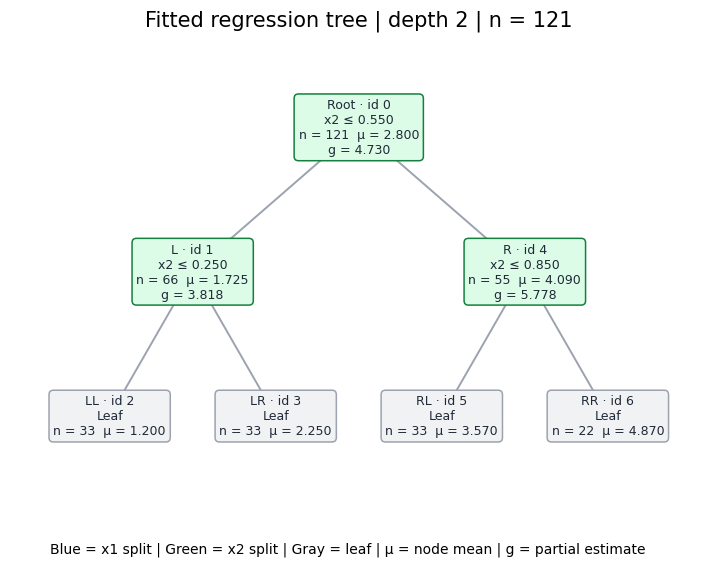

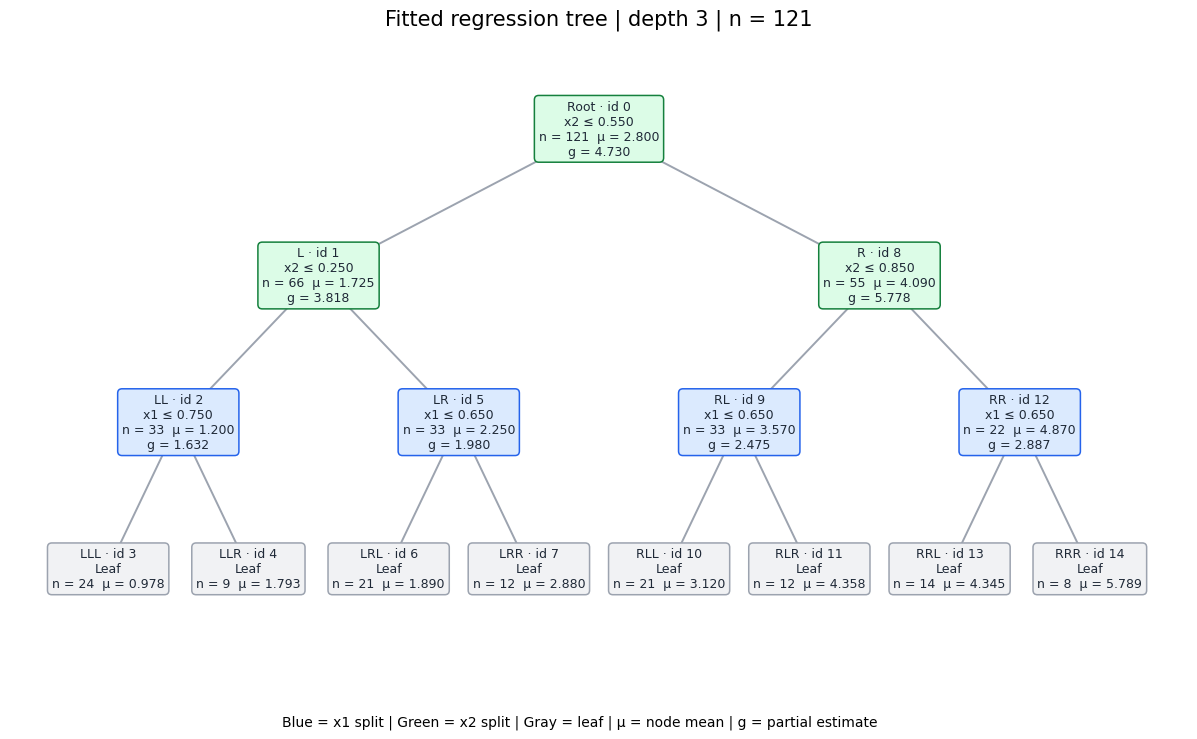

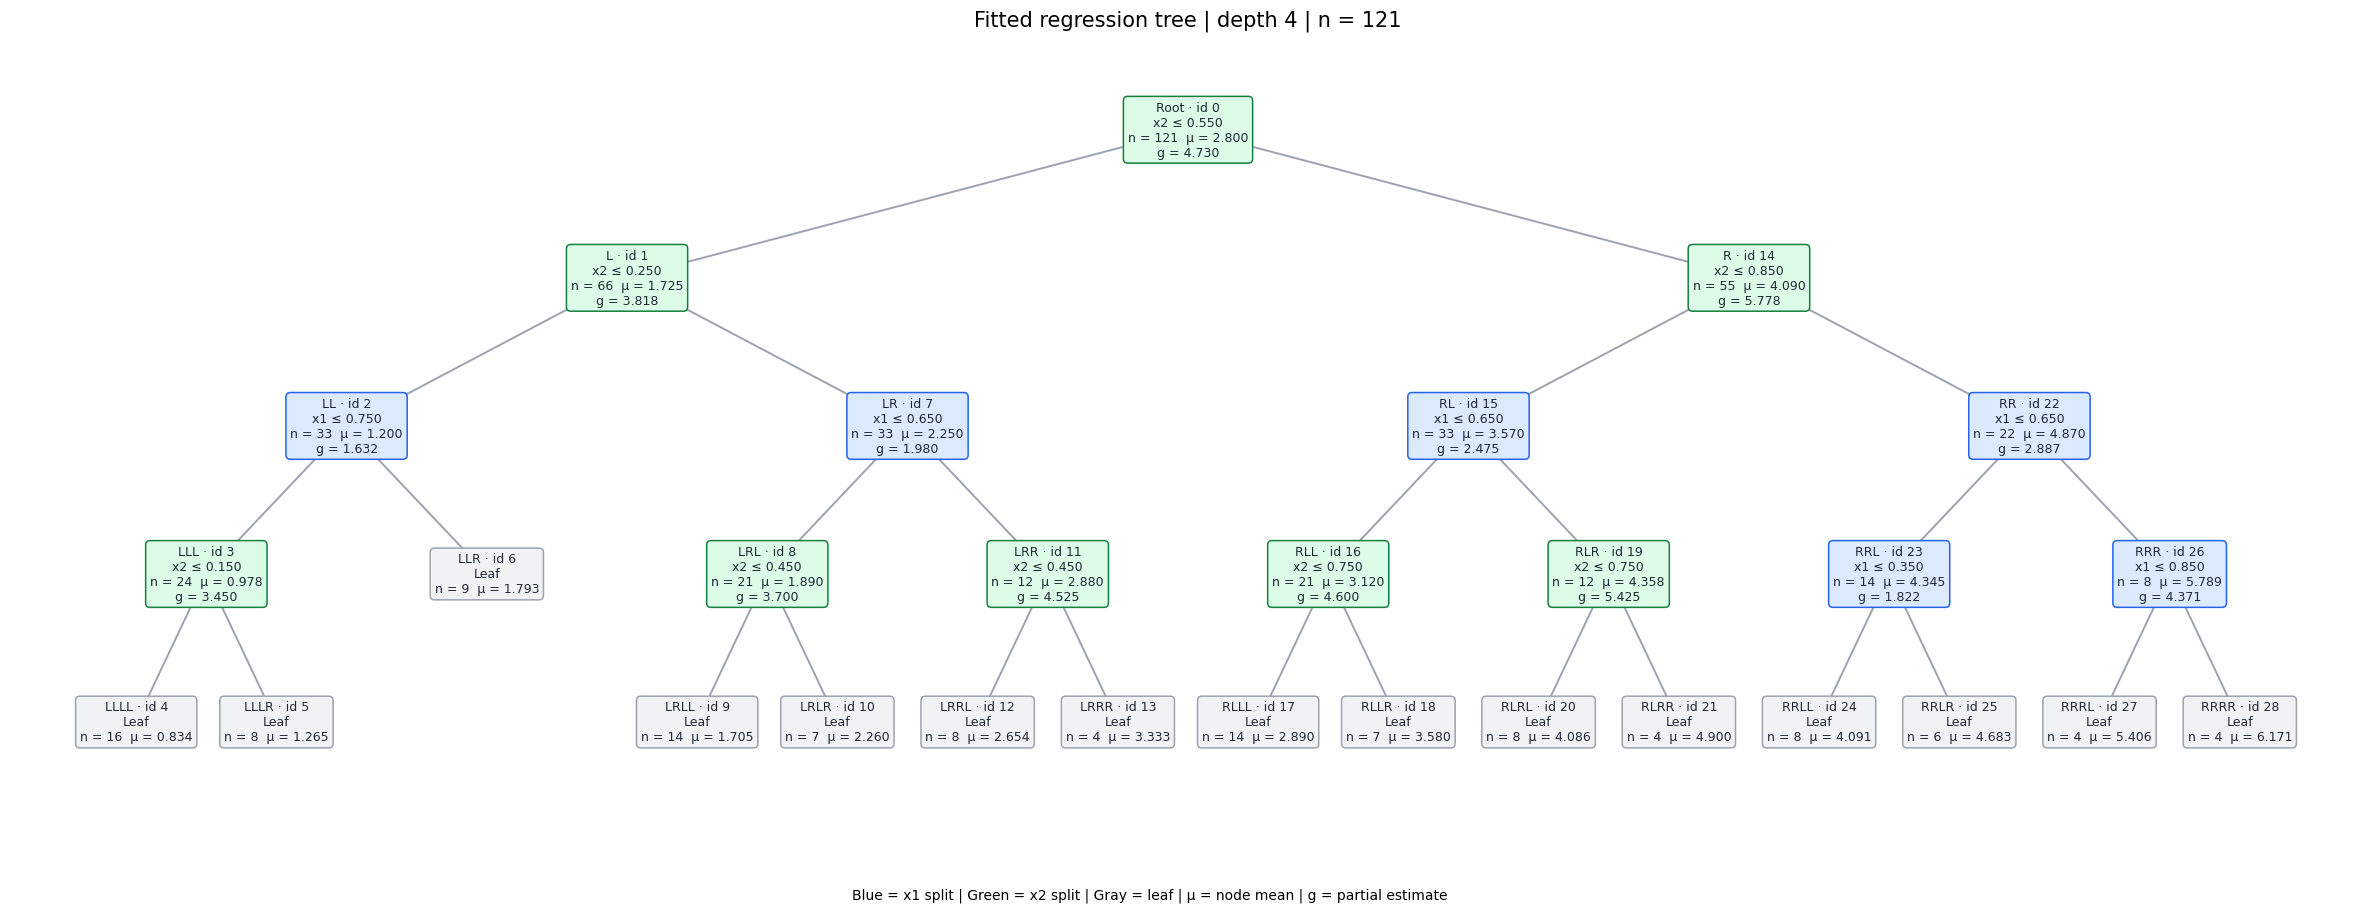

In [2]:
for depth,tree in trees.items():
    plot_fitted_tree(tree)

**Why:** Show why averaging is considered: three estimates of the same H22 from depth 2.

In [3]:
g_parent,m_parent = node_gradient(trees[2],'',1)
g_left,m_left = node_gradient(trees[2],'L',1)
g_right,m_right = node_gradient(trees[2],'R',1)
H22_PL = (g_parent-g_left)/(m_parent[1]-m_left[1])
H22_PR = (g_parent-g_right)/(m_parent[1]-m_right[1])
H22_LR = (g_right-g_left)/(m_right[1]-m_left[1])
H22_avg = (H22_PL+H22_PR+H22_LR)/3
display(pd.DataFrame({'comparison':['P–L','P–R','L–R','Mean','Truth'],'H22':[H22_PL,H22_PR,H22_LR,H22_avg,H_true[1,1]]}).round(4))

,comparison,H22
0,P–L,3.6473
1,P–R,3.6980
2,L–R,3.6742
3,Mean,3.6732
4,Truth,3.0000


All three overestimate H22. The long-interval contrast is a separation-weighted combination of the shorter contrasts, so they are not three independent observations.

**Why:** Show a deliberately selected incompatible configuration, not a representative random experiment.

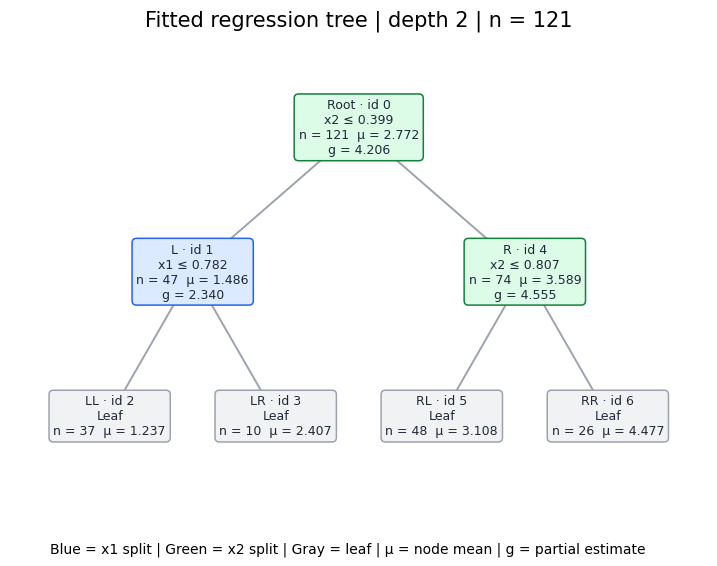

Root/L/R axes: [1, 0, 1]


In [4]:
rng = np.random.default_rng(44)
X_random = rng.uniform(0,1,(121,2))
tree_random = fit_tree(2,X_random,f(*X_random.T))
plot_fitted_tree(tree_random)
print('Root/L/R axes:',[int(node_info(tree_random,p)['axis']) for p in ('','L','R')])

## 2. Does averaging help?
Local pairs are parent–child or siblings; all pairs include every unordered pair of internal nodes. Compare only same-axis derivatives with exactly one changing effective coordinate. Missing entries are not zero. The explicit correction-based estimate is a separate test.

**Why:** Identify eligible pairs using effective location geometry, then compute the original difference quotients.

In [5]:
def internal_nodes(tree):
    nodes = {}
    def visit(path):
        v = node_info(tree,path)
        if v['axis'] < 0: return
        nodes[path] = v
        visit(path+'L'); visit(path+'R')
    visit('')
    return nodes

def classify_pair(axis_a,m_a,axis_b,m_b,tol=1e-8):
    if axis_a != axis_b or axis_a not in (0,1): return None
    delta_m = m_b-m_a
    if abs(delta_m[0]) > tol and abs(delta_m[1]) <= tol:
        return 'H11' if axis_a == 0 else 'H21'
    if abs(delta_m[0]) <= tol and abs(delta_m[1]) > tol:
        return 'H12' if axis_a == 0 else 'H22'
    return None

def eligible_pairs(tree,mode='local',tol=1e-8):
    nodes = internal_nodes(tree)
    if mode == 'local':
        candidates = []
        for p in nodes:
            l,r = p+'L',p+'R'
            if l in nodes: candidates.append((p,l))
            if r in nodes: candidates.append((p,r))
            if l in nodes and r in nodes: candidates.append((l,r))
    elif mode == 'all':
        candidates = combinations(nodes,2)
    else: raise ValueError('Use local or all')
    for p,q in candidates:
        a,b = nodes[p],nodes[q]
        entry = classify_pair(a['axis'],a['m'],b['axis'],b['m'],tol)
        if entry is not None: yield entry,p,q,a,b

def pair_estimates(tree,mode='local'):
    rows = []
    for entry,p,q,a,b in eligible_pairs(tree,mode):
        j = int(entry[-1])-1
        estimate = (b['g']-a['g'])/(b['m'][j]-a['m'][j])
        rows.append((entry,p or 'Root',q or 'Root',estimate))
    return pd.DataFrame(rows,columns=['entry','node A','node B','estimate'])


**Why:** Compare individual estimates and simple averages on the same depth-4 tree.

,entry,node A,node B,estimate
0,H22,Root,L,3.6473
1,H22,Root,R,3.6980
2,H22,L,R,3.6742
3,H12,LR,RL,1.6500
4,H12,LR,RR,1.7286
5,H21,LRL,LRR,1.6500
6,H22,LRL,RLL,3.0000
7,H22,LRR,RLR,3.0000
8,H12,RL,RR,1.8333
9,H21,RLL,RLR,1.6500


,local count,local mean,all count,all mean,truth
H11,3,5.0851,3,5.0851,4.0
H12,1,1.8333,3,1.7373,1.5
H21,2,1.6500,2,1.6500,1.5
H22,3,3.6732,5,3.4039,3.0


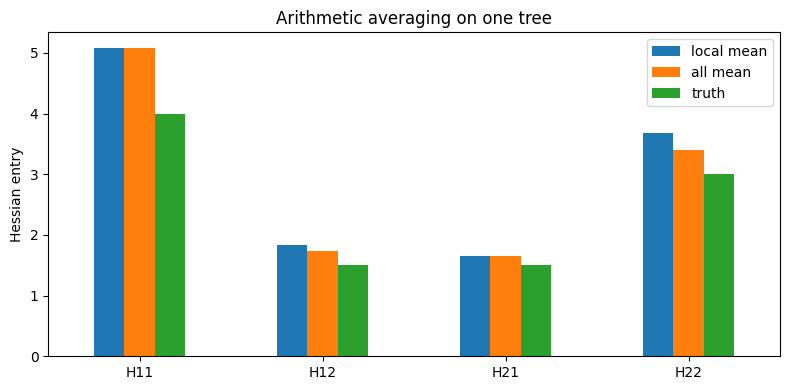

In [6]:
entries = ['H11','H12','H21','H22']
local = pair_estimates(trees[4],'local')
all_pairs = pair_estimates(trees[4],'all')
display(all_pairs.round(4))
summary = pd.DataFrame({'local count':local.groupby('entry').size(),'local mean':local.groupby('entry').estimate.mean(),
                        'all count':all_pairs.groupby('entry').size(),'all mean':all_pairs.groupby('entry').estimate.mean(),
                        'truth':pd.Series(dict(zip(entries,H_true.ravel())))}).reindex(entries)
display(summary.round(4))
summary[['local mean','all mean','truth']].plot.bar(rot=0,figsize=(8,4),ylabel='Hessian entry',title='Arithmetic averaging on one tree')
plt.tight_layout();plt.show()

All-pair averaging improves H12 and H22 on this grid, leaving H11 and H21 unchanged. This is one example, not a general superiority claim.

**Why:** Check the unequal-threshold correction using the estimated diagonal average, not the true Hessian.

In [7]:
g_left,m_left = node_gradient(trees[4],'LL',0)
g_right,m_right = node_gradient(trees[4],'LR',0)
delta_m = m_right-m_left
raw = (g_right-g_left)/delta_m[1]
corrected = (g_right-g_left-summary.loc['H11','all mean']*delta_m[0])/delta_m[1]
display(pd.DataFrame({'raw':[raw],'corrected':[corrected],'truth':[H_true[0,1]],'raw error':[abs(raw-H_true[0,1])],'corrected error':[abs(corrected-H_true[0,1])]}).round(4))

,raw,corrected,truth,raw error,corrected error
0,1.2667,1.883,1.5,0.2333,0.383


The ideal correction need not improve finite-sample accuracy; empirical derivative errors and diagonal-estimation error propagate into it.

## 3. Symmetry: three versions
A copies H12; B keeps independent H12 and H21; C averages those two entry-level estimates. All use the same all-pair diagonal averages.

**Why:** Compare the three treatments without altering their diagonal entries.

In [8]:
v = summary['all mean']
B = np.array([[v.H11,v.H12],[v.H21,v.H22]])
A = B.copy(); A[1,0] = A[0,1]
C = (B+B.T)/2
rows=[]
for name,H in [('A: copy H12',A),('B: independent',B),('C: symmetric mean',C)]:
    rows.append([name,*H.ravel(),np.linalg.norm(H-H_true,'fro'),abs(H[0,1]-H[1,0])])
display(pd.DataFrame(rows,columns=['version',*entries,'Frobenius error','symmetry gap']).round(4))
assert np.linalg.norm(C-H_true,'fro') <= np.linalg.norm(B-H_true,'fro') + 1e-12

,version,H11,H12,H21,H22,Frobenius error,symmetry gap
0,A: copy H12,5.0851,1.7373,1.7373,3.4039,1.2055,0.0000
1,B: independent,5.0851,1.7373,1.6500,3.4039,1.1914,0.0873
2,C: symmetric mean,5.0851,1.6937,1.6937,3.4039,1.1898,0.0000


For a symmetric true Hessian, symmetrization is an orthogonal projection, so Frobenius error cannot increase relative to B. This does not guarantee improvement over A, nor does a small symmetry gap guarantee accuracy.

## Appendix: count eligible cases
Counts only directly estimable pairs, not correction-based cases or independent observations. H12 and H21 remain separate for diagnosis. Frequency across independently sampled trees is deferred.

**Why:** Provide the requested counting function and check the observed coverage.

In [9]:
def count_hessian_cases(tree,mode='all',tol=1e-8):
    counts = dict.fromkeys(['H11','H12','H21','H22'],0)
    for entry,*_ in eligible_pairs(tree,mode,tol): counts[entry] += 1
    return counts
rows = [{'depth':d,'mode':mode,**count_hessian_cases(t,mode)} for d,t in trees.items() for mode in ('local','all')]
display(pd.DataFrame(rows))
display(pd.DataFrame([count_hessian_cases(tree_random)],index=['Random depth 2']))
assert count_hessian_cases(trees[2]) == {'H11':0,'H12':0,'H21':0,'H22':3}
assert count_hessian_cases(trees[4]) == {'H11':3,'H12':3,'H21':2,'H22':5}
assert all_pairs.groupby('entry').size().to_dict() == count_hessian_cases(trees[4])

,depth,mode,H11,H12,H21,H22
0,2,local,0,0,0,3
1,2,all,0,0,0,3
2,3,local,0,1,0,3
3,3,all,0,3,0,3
4,4,local,3,1,2,3
5,4,all,3,3,2,5


,H11,H12,H21,H22
Random depth 2,0,0,0,1


**For Nathan:** Which dependent comparisons should we pool, and how should they be weighted? Can the correction be made reliable? For a quadratic the Hessian is constant, justifying global pooling; this does not generalize automatically to a spatially varying Hessian. Next test: increase sample size and shrink boxes jointly. No 3D extension or large frequency simulation in this notebook.